# **Introduction to Support Vector Machines (SVMs)**

Support Vector Machines (**SVMs**) are **supervised learning models** used for **classification and regression** tasks in machine learning. These models analyze data and recognize patterns by constructing a **decision boundary** that separates different classes.

Given a set of labeled training examples, an **SVM algorithm** builds a model that classifies **new data points** based on their position relative to this boundary, making it a **non-probabilistic binary linear classifier**.

An **SVM model** represents training examples as **points in space**, ensuring that examples from different categories are separated by a **distinct margin**. The objective of the SVM is to find the **optimal hyperplane** that maximizes this margin, creating the **best possible separation** between classes. New data points are then classified based on their location in relation to this **hyperplane**.

---



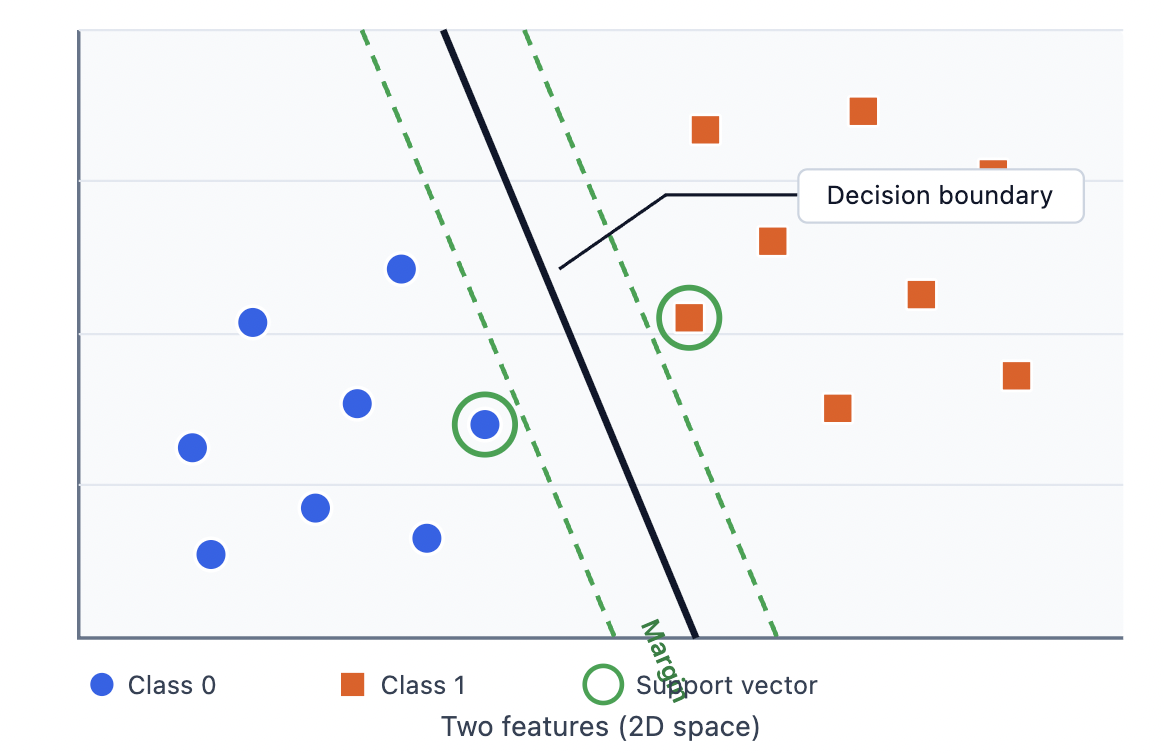

## **Advantages of Support Vector Machines**
✔ **Effective in High-Dimensional Spaces**  
   - SVMs perform well when the number of **features is large**, making them useful for **complex datasets**.

✔ **Works Well with Small Datasets**  
   - Even when the **number of features exceeds** the number of **training samples**, SVMs can still perform effectively.

✔ **Memory Efficient**  
   - SVMs use only a subset of the **training points**, called **support vectors**, in the **decision function**, reducing memory usage.

✔ **Versatile with Kernel Functions**  
   - Different **kernel functions** (such as **linear, polynomial, and radial basis function (RBF)**) can be used to **transform data** into a **higher-dimensional space**, allowing SVMs to handle **non-linear classification tasks**.

---

## **Disadvantages of Support Vector Machines**
❌ **Poor Performance with Large Feature-to-Sample Ratios**  
   - When the **number of features far exceeds** the **number of training samples**, SVMs may not **generalize well**.

❌ **Lack of Direct Probability Estimates**  
   - SVMs do **not inherently provide probability estimates** for predictions. However, methods such as **Platt scaling** can be used to approximate probabilities.

❌ **Computational Complexity for Large Datasets**  
   - Training an **SVM with a large dataset** can be **computationally expensive**, especially with **non-linear kernels**.

---

Despite these limitations, **SVMs remain a powerful tool** in machine learning, particularly for **classification problems** where defining a **clear boundary** is essential. By selecting **appropriate kernels** and **tuning parameters**, SVMs can effectively handle **complex datasets** and provide **high accuracy** in various applications.


# **How SVM Works**

To better understand how **Support Vector Machines (SVMs)** work, let's visualize the concept using figures.

---

## **1. Separating Two Classes**
Imagine a dataset with two different classes:

- **Red squares** represent one class.  
- **Blue circles** represent another class.  

We want to find a way to **separate these two classes** in a **two-dimensional feature space**.

Below, we see an example of different possible **decision boundaries** (**green lines**) that can be drawn to separate the two classes:



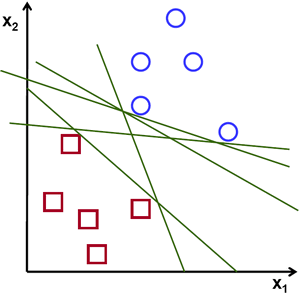


However, not all of these decision boundaries are **optimal**.

Some lines are **too close** to certain points, making classification **less robust**. The goal of **SVM** is to find the **best decision boundary** that provides the **largest possible margin** between the two classes.

---

## **2. Finding the Optimal Hyperplane**
SVM selects the **optimal hyperplane**, which **maximizes the margin** between the **two closest points** of different classes (**support vectors**). The following figure illustrates this concept:








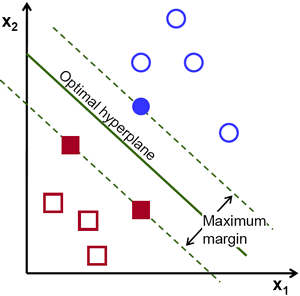



- The **solid green line** represents the **optimal hyperplane**.  
- The **dashed green lines** indicate the **margin boundaries**.  
- The **closest points** to the margin are called **support vectors** (**highlighted in red and blue**).  

---

## **3. Maximizing the Margin**
- The **margin** is the **distance** between the **hyperplane** and the **nearest data points** (**support vectors**).  
- **SVM tries to maximize this margin** to make the **classification more generalizable and robust**.  
- Any **slight movement** of **support vectors** can **change the decision boundary**, which is why they play a **crucial role in SVM**.  

---

## **4. Non-Linearly Separable Data & The Kernel Trick**

Sometimes, data **cannot be separated** with a **straight line** (**linear hyperplane**). For example, if the data **forms a circular pattern**, a **linear classifier** will **fail**. To handle such cases, **SVM uses the kernel trick**, which **maps data** into a **higher-dimensional space** where a **linear separation is possible**.

### **The Kernel Trick allows SVM to transform complex data into a space where separation is easier.**
Common **kernel types** include:

- **Linear Kernel** – When data is **already linearly separable**.  
- **Polynomial Kernel** – Creates a **more flexible decision boundary** for complex data.  
- **Radial Basis Function (RBF) Kernel** – Maps data into an **infinite-dimensional space**, making it **highly effective** for complex patterns.  

---

### **The following visualization illustrates how the kernel trick works:**

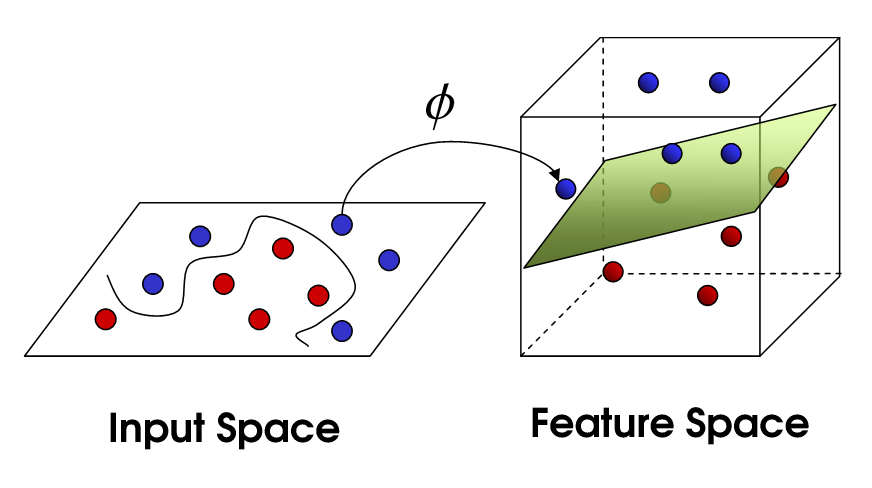

- The **left side** represents the **input space**, where the data is **not linearly separable**.  
- The **transformation function** maps the data into a **higher-dimensional feature space**.  
- In this **higher-dimensional space**, a **linear hyperplane** can now effectively **separate the classes**.  

## Step 1: Load and Prepare the Dataset
Before training an SVM model, we need to:
- Load the dataset.
- Identify **numerical and categorical** features.
- Convert **categorical features** into appropriate labels.
- Remove missing values.
- Define the **target variable**.

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('/content/customer_churn_modified.csv')
df.head()

,age,account_length,contract,monthly_charges,total_charges,service_calls,internet_service,additional_services,churn
0,56,115,Month-to-Month,115.420093,13273.310681,0,No Internet,0,1
1,69,15,One Year,76.161217,1142.418262,1,No Internet,4,0
2,46,119,One Year,38.430518,4573.231626,2,DSL,2,0
3,32,28,One Year,97.915910,2741.645478,2,Fiber Optic,4,0
4,60,39,Month-to-Month,74.273799,2896.678161,2,Fiber Optic,3,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  1000 non-null   int64  
 1   account_length       1000 non-null   int64  
 2   contract             1000 non-null   object 
 3   monthly_charges      1000 non-null   float64
 4   total_charges        1000 non-null   float64
 5   service_calls        1000 non-null   int64  
 6   internet_service     1000 non-null   object 
 7   additional_services  1000 non-null   int64  
 8   churn                1000 non-null   int64  
dtypes: float64(2), int64(5), object(2)
memory usage: 70.4+ KB


In [4]:
target_column = 'churn'

num_features = df.select_dtypes(include='number').columns.tolist()
cat_features = df.select_dtypes(include='object').columns.tolist()

In [5]:
num_features.remove('churn')
num_features

['age',
 'account_length',
 'monthly_charges',
 'total_charges',
 'service_calls',
 'additional_services']

In [6]:
cat_features

['contract', 'internet_service']

## Step 2: Understanding ColumnTransformer
A `ColumnTransformer` allows us to apply different preprocessing steps to different types of columns in a single step:
- **Standardizes numerical features** using `StandardScaler()`.
- **One-Hot Encodes categorical features** using `OneHotEncoder()`.
This approach ensures that categorical data is transformed correctly before being used in the SVM model.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [8]:
preprocessor = ColumnTransformer([
  ('num', StandardScaler(), num_features),
  ('cat', OneHotEncoder(drop='first'),cat_features)
])

In [9]:
preprocessor

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['age', 'account_length', 'monthly_charges',
                                  'total_charges', 'service_calls',
                                  'additional_services']),
                                ('cat', OneHotEncoder(drop='first'),
                                 ['contract', 'internet_service'])])

## Step 3: Understanding Pipelines
A `Pipeline` automates the machine learning workflow by chaining multiple steps together:
1. **Preprocessing** (handled by `ColumnTransformer`).
2. **Training an SVM model**.

**Advantages of Pipelines:**
- **Prevents data leakage** by applying transformations only on training data.
- **Ensures a clean workflow** by combining preprocessing and model training in one step.
- **Simplifies hyperparameter tuning** by allowing modifications to be applied across the pipeline.

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split

# Define my SVM pineline
svm_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('svm', SVC())
])


In [11]:
svm_pipeline

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'account_length',
                                                   'monthly_charges',
                                                   'total_charges',
                                                   'service_calls',
                                                   'additional_services']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['contract',
                                                   'internet_service'])])),
                ('svm', SVC())])

In [12]:
# Split data into training and testing sets
X = df.drop(target_column, axis=1)
y = df[target_column]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [13]:
# Train the model
svm_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'account_length',
                                                   'monthly_charges',
                                                   'total_charges',
                                                   'service_calls',
                                                   'additional_services']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['contract',
                                                   'internet_service'])])),
                ('svm', SVC())])

In [14]:
# Predict and evaluate
y_pred = svm_pipeline.predict(X_test)

In [15]:
from sklearn.metrics import classification_report

In [16]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       146
           1       0.98      0.93      0.95        54

    accuracy                           0.97       200
   macro avg       0.98      0.96      0.97       200
weighted avg       0.98      0.97      0.97       200



## Step 4: Optimize SVM using GridSearchCV
`GridSearchCV` is used to search for the best combination of hyperparameters by:
- Performing **cross-validation** to evaluate different parameter settings.
- Improving model performance by **selecting optimal hyperparameters**.

**Hyperparameters being tuned:**
- `C`: Regularization parameter that controls model complexity.
- `gamma`: Controls how much influence a single training sample has.
- `kernel`: Defines how SVM separates data (linear, polynomial, RBF, etc.).

In [17]:
from sklearn.model_selection import GridSearchCV

# Define parameter grid
param_grid = {
    'svm__C': [0.1, 1, 10, 100],
    'svm__gamma': ['scale', 0.01, 0.1, 1, 10],
    'svm__kernel': ['linear', 'poly', 'rbf', 'sigmoid']
}

In [18]:
# Perform Grid Search
grid_search = GridSearchCV(svm_pipeline, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocess',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['age',
                                                                          'account_length',
                                                                          'monthly_charges',
                                                                          'total_charges',
                                                                          'service_calls',
                                                                          'additional_services']),
                                                                        ('cat',
                                                                         OneHotEncoder(drop='first'),
                                                                         ['contract',
                                                                          'internet_service'])])),
                                       ('svm', SVC())]),
             param_grid={'svm__C': [0.1, 1, 10, 100],
                         'svm__gamma': ['scale', 0.01, 0.1, 1, 10],
                         'svm__kernel': ['linear', 'poly', 'rbf', 'sigmoid']},
             scoring='accuracy')

In [19]:
# Print best parameters
print("Best Parameters:", grid_search.best_params_)

Best Parameters: {'svm__C': 10, 'svm__gamma': 0.1, 'svm__kernel': 'rbf'}


## Step 5: Evaluate the Optimized Model
Once the best hyperparameters are selected, we evaluate the model's performance using:
- **Accuracy**.
- **Precision, Recall, and F1-score** from a classification report.

In [20]:
# Get the best model
best_model = grid_search.best_estimator_
best_model

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'account_length',
                                                   'monthly_charges',
                                                   'total_charges',
                                                   'service_calls',
                                                   'additional_services']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['contract',
                                                   'internet_service'])])),
                ('svm', SVC(C=10, gamma=0.1))])

In [21]:
# Predict using the best model
y_pred_best = best_model.predict(X_test)

In [22]:
# Print classification report
print(classification_report(y_test, y_pred_best))

              precision    recall  f1-score   support

           0       0.99      0.98      0.99       146
           1       0.95      0.98      0.96        54

    accuracy                           0.98       200
   macro avg       0.97      0.98      0.97       200
weighted avg       0.98      0.98      0.98       200



**Plot ROC Curve**

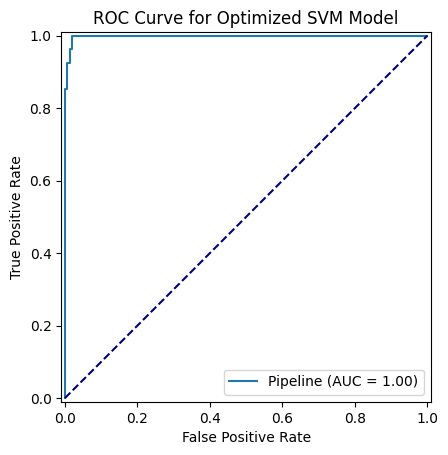

In [23]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

RocCurveDisplay.from_estimator(best_model, X_test, y_test)

plt.plot([0,1],[0,1],color='navy',linestyle='--')
plt.title('ROC Curve for Optimized SVM Model')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

## Step 6: Feature Importance using Permutation Importance
Unlike tree-based models, SVM does not provide built-in feature importance. Instead, we use **Permutation Importance**, which measures how much each feature contributes to the classification task by randomly shuffling feature values and measuring the effect on model accuracy.

Feature Importance Scores (Sorted):

contract_Two Years: 0.2170
monthly_charges: 0.1645
additional_services: 0.0880
total_charges: 0.0390
service_calls: 0.0025
contract_One Year: 0.0005
account_length: -0.0030
age: -0.0055


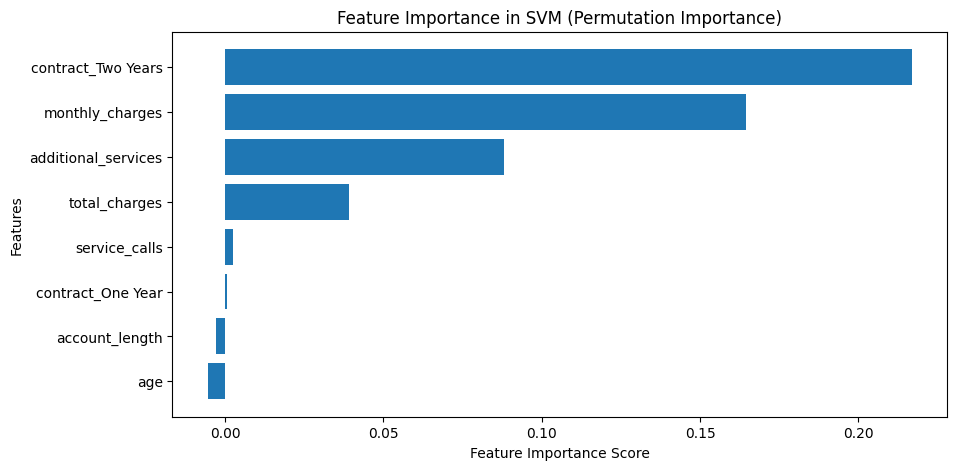

In [24]:
# Import necessary libraries
from sklearn.inspection import permutation_importance

# Compute permutation importance for the best SVM model
importance = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=42)

# Get feature names from the preprocessor (categorical and numerical features)
feature_names = num_features + list(best_model.named_steps['preprocess'].named_transformers_['cat'].get_feature_names_out())

# Sort feature importance by descending order
sorted_idx = importance.importances_mean.argsort()[::-1]

# Print sorted feature importance scores
sorted_features = [(feature_names[i], importance.importances_mean[i]) for i in sorted_idx]

print("Feature Importance Scores (Sorted):\n")
for feature, score in sorted_features:
    print(f"{feature}: {score:.4f}")

# Plot feature importance
plt.figure(figsize=(10, 5))
plt.barh([feature_names[i] for i in sorted_idx[::-1]], importance.importances_mean[sorted_idx[::-1]])
plt.xlabel("Feature Importance Score")
plt.ylabel("Features")
plt.title("Feature Importance in SVM (Permutation Importance)")
plt.show()




### **Feature Importance Analysis Output**

The bar chart above represents the **Permutation Importance** of each feature in predicting customer churn. This tells us which factors have the biggest influence on whether a customer stays or leaves.

By identifying the most important factors, businesses can develop targeted strategies to improve retention.

For example:

- If the model finds that customers with **One-Year Contracts** are more likely to churn, the company can offer renewal incentives to keep them.
- If **high monthly charges** increase churn, the company might adjust pricing plans or offer discounts to at-risk customers.

### Understanding Positive vs. Negative Importance

**High Positive Importance:** Features that increase the likelihood of churn as their values increase.

- Example: **Higher `monthly_charges` → More churn** (customers may leave due to cost concerns).

**High Negative Importance:** Features that decrease churn likelihood as their values increase.

- Example: **More `additional_services` → Less churn** (customers who use more services are more engaged).

**Near Zero or Negative Importance:** Features that have little or no effect on churn.

- Example: **`age` and `account_length` → Not strong indicators** of whether a customer will leave.
